<a href="https://colab.research.google.com/github/MFerrugem/RNA/blob/main/times_futebol_vgg16_transfer_learning_down.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificação de times de futebol com transfer learning (VGG16 + TensorFlow 2.x)

Reaproveita a **VGG16 pré-treinada no ImageNet** como extratora de características e treina apenas as camadas finais para reconhecer times de futebol (por exemplo, escudos, camisas ou jogadores uniformizados).

**Etapas**
1. Carregar o conjunto de dados a partir de pastas (uma pasta por time).
2. Montar o modelo: base VGG16 congelada + `GlobalAveragePooling2D` + camadas `Dense`.
3. Treinar apenas as novas camadas (extração de características).
4. *Fine-tuning* opcional do último bloco convolucional.
5. Avaliar (acurácia, matriz de confusão), testar uma imagem e salvar o modelo.

**Dataset usado por padrão:** *OM x PSG T-Shirt Detection* (Olympique de Marseille x Paris Saint-Germain), 600 fotos por time com jogadores de camisa, de github.com/IgorMeloS/OMxPSG-T-Shirt-Detection. O notebook baixa só a pasta `dataset` do repositório.

> Aviso: as fotos vieram das páginas dos clubes no Facebook e provavelmente pertencem a eles. Use apenas para estudo e não redistribua as imagens nem publique o modelo sem verificar os direitos. São apenas 2 classes, o que serve para validar o pipeline. Os patrocinadores e as cores aparecem em muitas fotos, e o modelo pode aprender esses atalhos.

**Para usar seu próprio dataset**, organize uma pasta com uma subpasta por time (o nome da pasta é o rótulo) e ajuste `DATA_DIR` na seção de configuração:

```
meu_dataset/
├── flamengo/    img001.jpg, img002.jpg, ...
├── gremio/      ...
└── ...
```

Recomendação: pelo menos 100 imagens por time e quantidades parecidas entre as classes.

In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPUs disponíveis:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs disponíveis: []


## 1. Configuração e download do dataset

A célula abaixo baixa **apenas a pasta `dataset`** do repositório (usa `git` com *sparse checkout*, sem trazer o resto). Se a pasta já existir, o download é pulado. Requer `git` instalado e acesso à internet (no Google Colab já funciona).

Para usar outro dataset, defina `USAR_OMXPSG = False` e aponte `DATA_DIR` para a sua pasta.

In [2]:
import subprocess

USAR_OMXPSG = True               # False para usar uma pasta sua
REPO_URL = "https://github.com/IgorMeloS/OMxPSG-T-Shirt-Detection.git"
REPO_DIR = "OMxPSG-T-Shirt-Detection"

DATA_DIR = os.path.join(REPO_DIR, "dataset") if USAR_OMXPSG else "meu_dataset"

IMG_SIZE = (224, 224)           # tamanho de entrada da VGG16
BATCH_SIZE = 32
VAL_SPLIT = 0.30                # 30% para validação + teste (divididos meio a meio)
EPOCHS_HEAD = 20                # épocas treinando só as camadas novas
EPOCHS_FINE = 10                # épocas do fine-tuning (opcional)
WEIGHTS = "imagenet"            # use None apenas para testar o código sem baixar pesos


def baixar_omxpsg():
    """Baixa só a pasta 'dataset' do repositório OM x PSG (cerca de 360 MB)."""
    if os.path.isdir(DATA_DIR) and len(os.listdir(DATA_DIR)) >= 2:
        print(f"Dataset já existe em '{DATA_DIR}'. Download ignorado.")
        return
    print("Baixando o dataset (cerca de 360 MB). Pode levar alguns minutos...")
    subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
                    REPO_URL, REPO_DIR], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "sparse-checkout", "set", "dataset"], check=True)
    print("Download concluído.")


if USAR_OMXPSG:
    baixar_omxpsg()

# Resumo do que foi baixado
for pasta in sorted(os.listdir(DATA_DIR)):
    caminho = os.path.join(DATA_DIR, pasta)
    if os.path.isdir(caminho):
        print(f"{pasta:<12} {len(os.listdir(caminho))} arquivos")

Baixando o dataset (cerca de 360 MB). Pode levar alguns minutos...
Download concluído.
OM           600 arquivos
PSG          600 arquivos


In [3]:
# Verifica se todas as imagens abrem corretamente (descarta arquivos corrompidos)
from PIL import Image

corrompidas = []
for raiz, _, arquivos in os.walk(DATA_DIR):
    for nome in arquivos:
        caminho = os.path.join(raiz, nome)
        try:
            with Image.open(caminho) as im:
                im.verify()
        except Exception:
            corrompidas.append(caminho)

print(f"Imagens corrompidas: {len(corrompidas)}")
for c in corrompidas:
    os.remove(c)
    print("Removida:", c)

Imagens corrompidas: 0


## 2. Carregar os dados

`image_dataset_from_directory` lê as pastas, redimensiona as imagens e gera os rótulos. Os dados são divididos em **treino (70%)**, **validação (15%)** e **teste (15%)**. O conjunto de teste só é usado ao final.

In [4]:
assert os.path.isdir(DATA_DIR), f"Pasta '{DATA_DIR}' não encontrada. Veja a estrutura esperada acima."

common = dict(
    directory=DATA_DIR,
    validation_split=VAL_SPLIT,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)
train_ds = tf.keras.utils.image_dataset_from_directory(subset="training", **common)
holdout_ds = tf.keras.utils.image_dataset_from_directory(subset="validation", **common)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Times (classes):", class_names)
assert num_classes >= 2, "São necessárias ao menos 2 pastas (times)."

# Divide o hold-out em validação e teste
n_batches = tf.data.experimental.cardinality(holdout_ds).numpy()
assert n_batches >= 2, "Poucas imagens: reduza BATCH_SIZE ou adicione mais dados."
test_ds = holdout_ds.take(n_batches // 2)
val_ds = holdout_ds.skip(n_batches // 2)

print("Lotes -> treino:", tf.data.experimental.cardinality(train_ds).numpy(),
      "| validação:", tf.data.experimental.cardinality(val_ds).numpy(),
      "| teste:", tf.data.experimental.cardinality(test_ds).numpy())

Found 1200 files belonging to 2 classes.
Using 840 files for training.
Found 1200 files belonging to 2 classes.
Using 360 files for validation.
Times (classes): ['OM', 'PSG']
Lotes -> treino: 27 | validação: 6 | teste: 6


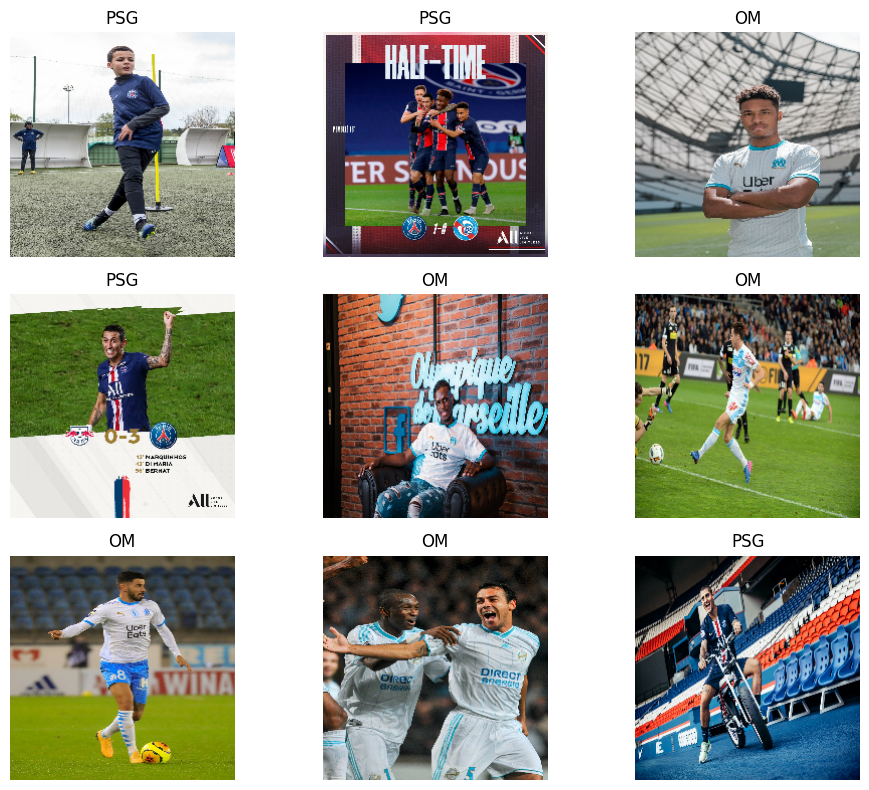

In [5]:
# Amostra das imagens de treino
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()

In [6]:
# Distribuição das classes no treino e pesos para compensar desbalanceamento
counts = np.zeros(num_classes, dtype=int)
for _, labels in train_ds:
    counts += np.bincount(labels.numpy(), minlength=num_classes)

for name, c in zip(class_names, counts):
    print(f"{name:<20} {c} imagens")

total = counts.sum()
class_weight = {i: float(total / (num_classes * c)) for i, c in enumerate(counts)}
print("Pesos de classe:", {class_names[i]: round(w, 2) for i, w in class_weight.items()})

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

OM                   441 imagens
PSG                  399 imagens
Pesos de classe: {'OM': 0.95, 'PSG': 1.05}


## 3. Modelo: VGG16 congelada + camadas novas

- `include_top=False` remove as camadas de classificação originais (1000 classes do ImageNet).
- `base.trainable = False` congela a base: seus pesos não são atualizados no primeiro treino.
- `GlobalAveragePooling2D` resume cada mapa de características em um número, o que reduz bastante os parâmetros em relação ao `Flatten`.
- Camadas `Dense` finais aprendem a separar os times.
- O `preprocess_input` da VGG16 e o *data augmentation* ficam **dentro do modelo**, então o mesmo pré-processamento vale no treino e na inferência.

> Atenção ao *data augmentation*: o espelhamento horizontal funciona bem para camisas e jogadores, mas pode atrapalhar se houver texto ou assimetrias importantes (como escudos com letras). Nesse caso, remova `RandomFlip`.

In [7]:
base = VGG16(weights=WEIGHTS, include_top=False, input_shape=IMG_SIZE + (3,))
base.trainable = False

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="augmentation")

inputs = layers.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)               # só é aplicado durante o treino
x = preprocess_input(x)                     # pré-processamento original da VGG16
x = base(x, training=False)                 # base congelada em modo de inferência
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs, name="vgg16_times_futebol")
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16_times_futebol"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ augmentation[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ augmentation[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ augmentation[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    131,328 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 2)         │        514 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,846,530 (56.64 MB)

 Trainable params: 131,842 (515.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## 4. Treino das camadas novas

Somente `Dense` e o restante da "cabeça" são atualizados. Os *callbacks* interrompem o treino se a validação parar de melhorar, reduzem a taxa de aprendizado em platôs e guardam o melhor modelo.

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
    tf.keras.callbacks.ModelCheckpoint("melhor_modelo_times.keras", monitor="val_loss", save_best_only=True),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    class_weight=class_weight,
    callbacks=callbacks,
)

Epoch 1/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 727s 26s/step - accuracy: 0.7036 - loss: 1.9078 - val_accuracy: 0.8810 - val_loss: 0.4196 - learning_rate: 0.0010
Epoch 2/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 709s 26s/step - accuracy: 0.8167 - loss: 0.9508 - val_accuracy: 0.9107 - val_loss: 0.3873 - learning_rate: 0.0010
Epoch 3/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 683s 25s/step - accuracy: 0.8667 - loss: 0.6838 - val_accuracy: 0.9286 - val_loss: 0.2354 - learning_rate: 0.0010
Epoch 4/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 684s 25s/step - accuracy: 0.8810 - loss: 0.5537 - val_accuracy: 0.9643 - val_loss: 0.1648 - learning_rate: 0.0010
Epoch 5/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 685s 26s/step - accuracy: 0.8702 - loss: 0.5009 - val_accuracy: 0.9583 - val_loss: 0.1668 - learning_rate: 0.0010
Epoch 6/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 682s 25s/step - accuracy: 0.8631 - loss: 0.5418 - val_accuracy: 0.9286 - val_loss: 0.2152 - learning_rate: 0.0010
Epoch 7/20
 5/27 ━━━━━━━━━━━━━━━━━━━━ 7:57 22s/step - accuracy: 0.9190 - loss: 0.3268

In [ ]:
def plot_history(histories, titulo=""):
    acc = sum([h.history["accuracy"] for h in histories], [])
    val_acc = sum([h.history["val_accuracy"] for h in histories], [])
    loss = sum([h.history["loss"] for h in histories], [])
    val_loss = sum([h.history["val_loss"] for h in histories], [])

    plt.figure(figsize=(11, 4))
    plt.subplot(1, 2, 1)
    plt.plot(acc, label="treino"); plt.plot(val_acc, label="validação")
    plt.title("Acurácia " + titulo); plt.xlabel("época"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(loss, label="treino"); plt.plot(val_loss, label="validação")
    plt.title("Perda " + titulo); plt.xlabel("época"); plt.legend()
    plt.tight_layout(); plt.show()

plot_history([history])

## 5. Fine-tuning (opcional)

Depois que a "cabeça" convergiu, libera-se apenas o **último bloco convolucional** (`block5`) da VGG16 e treina-se com taxa de aprendizado bem pequena. Isso costuma adicionar alguns pontos de acurácia, principalmente quando os times são visualmente parecidos. Os blocos iniciais, que detectam bordas e texturas genéricas, continuam congelados.

Se a validação piorar, pule esta etapa ou use o modelo salvo antes dela.

In [ ]:
base.trainable = True
for layer in base.layers:
    layer.trainable = layer.name.startswith("block5")

print("Camadas treináveis na base:", [l.name for l in base.layers if l.trainable])

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),   # taxa baixa para não destruir os pesos pré-treinados
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_fine = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("melhor_modelo_times_finetuned.keras", monitor="val_loss", save_best_only=True),
]

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    class_weight=class_weight,
    callbacks=callbacks_fine,
)

plot_history([history, history_fine], titulo="(cabeça + fine-tuning)")

## 6. Avaliação no conjunto de teste

O teste não foi usado em nenhum momento do treino ou da escolha do melhor modelo.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Acurácia no teste: {test_acc:.3f} | perda: {test_loss:.3f}")

y_true, y_pred = [], []
for images, labels in test_ds:
    probs = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(probs, axis=1))

print()
print(classification_report(y_true, y_pred, labels=range(num_classes),
                            target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(num_classes))
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Matriz de confusão (teste)")
plt.tight_layout()
plt.show()

## 7. Classificar uma imagem nova

In [ ]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

def prever_time(caminho_imagem, top=3):
    img = load_img(caminho_imagem, target_size=IMG_SIZE)
    x = np.expand_dims(img_to_array(img), axis=0)      # (1, 224, 224, 3); o preprocess_input já está no modelo
    probs = model.predict(x, verbose=0)[0]
    idx = np.argsort(probs)[::-1][:top]

    plt.imshow(img); plt.axis("off")
    plt.title(f"{class_names[idx[0]]} ({probs[idx[0]]*100:.1f}%)")
    plt.show()
    for i in idx:
        print(f"{class_names[i]:<20} {probs[i]*100:6.2f}%")

# Exemplo: altere para o caminho de uma imagem sua
# prever_time("teste/camisa.jpg")

## 8. Salvar o modelo e os nomes das classes

Guarde também a lista de classes: a ordem delas define o significado de cada saída do modelo.

In [ ]:
model.save("classificador_times_vgg16.keras")
with open("classes_times.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)

print("Modelo salvo em 'classificador_times_vgg16.keras' e classes em 'classes_times.json'")

# Para recarregar depois:
# model = tf.keras.models.load_model("classificador_times_vgg16.keras")
# class_names = json.load(open("classes_times.json", encoding="utf-8"))

## Dicas para melhorar os resultados

- **Mais dados e mais variedade:** diferentes ângulos, iluminação, estádios e temporadas (as camisas mudam a cada ano). É o fator que mais pesa.
- **Defina bem o problema:** reconhecer escudos é bem mais fácil do que reconhecer o time pela camisa em fotos de jogo. Misturar tipos de imagem na mesma classe prejudica o modelo.
- **Equilíbrio entre classes:** o notebook já calcula pesos de classe, mas ter quantidades parecidas é melhor.
- **Alternativas à VGG16:** `EfficientNetB0`, `ResNet50V2` ou `MobileNetV2` costumam render mais com menos parâmetros. A estrutura do notebook é a mesma; troque a base e o respectivo `preprocess_input`.
- **Direitos de imagem:** escudos e fotos de times podem ter direitos autorais. Confira a licença do seu conjunto de dados antes de publicar o modelo.